In [22]:
import numpy as np

In [23]:
class Agent:
    def __init__(self, x, y, status="susceptible"):
        self.x = x
        self.y = y
        self.status = status

    movement = dict({"up": (-1, 0), "down": (1, 0), "left": (0, -1), "right": (0, 1), "stay": (0, 0)})

    def move(self, direction):
        if direction in Agent.movement:
            dx, dy = Agent.movement[direction]
            self.x = max(0, min(19, self.x + dx))
            self.y = max(0, min(19, self.y + dy))

    def infect(self, p):
        if np.random.rand() < p:
            self.status = "infected"

    def recover(self, q):
        if np.random.rand() < q:
            self.status = "recovered"

    def is_susceptible(self):
        return self.status == "susceptible"

    def is_infected(self):
        return self.status == "infected"

    def is_recovered(self):
        return self.status == "recovered"

In [24]:
def initialize_agent_grid(grid_size, num_susceptible, num_infected, num_recovered):
    agents = []
    for _ in range(num_susceptible):
        x, y = np.random.randint(0, grid_size-1), np.random.randint(0, grid_size-1)
        agents.append(Agent(x, y, 'susceptible'))
    for _ in range(num_infected):
        x, y = np.random.randint(0, grid_size-1), np.random.randint(0, grid_size-1)
        agents.append(Agent(x, y, 'infected'))
    for _ in range(num_recovered):
        x, y = np.random.randint(0, grid_size-1), np.random.randint(0, grid_size-1)
        agents.append(Agent(x, y, 'recovered'))
    return agents

In [25]:
agents = initialize_agent_grid(grid_size=20, num_susceptible=195, num_infected=5, num_recovered=0)

In [26]:
# Parameter definition
transmission_p = 0.1
recovery_q = 0.5

In [27]:
def simulate_pandemic(agents, q, p, time_steps=300):
    susceptible_counts = []
    infected_counts = []
    recovered_counts = []

    for _ in range(time_steps):
        for agent in agents:
            direction = np.random.choice(list(Agent.movement.keys()))
            agent.move(direction)

        for x in range(20):
            for y in range(20):
                cell_agents = [agent for agent in agents if agent.x == x and agent.y == y]
                if any(agent.is_infected() for agent in cell_agents):
                    for agent in cell_agents:
                        if agent.is_infected():
                            agent.recover(q=q)
                    for agent in cell_agents:
                        if agent.is_susceptible():
                            agent.infect(p=p)

        num_susceptible = sum(agent.is_susceptible() for agent in agents)
        num_infected = sum(agent.is_infected() for agent in agents)
        num_recovered = sum(agent.is_recovered() for agent in agents)

        susceptible_counts.append(num_susceptible)
        infected_counts.append(num_infected)
        recovered_counts.append(num_recovered)

    return susceptible_counts, infected_counts, recovered_counts

## Simulation

In [28]:
susceptible_counts, infected_counts, recovered_counts = simulate_pandemic(agents, recovery_q, transmission_p, 300)

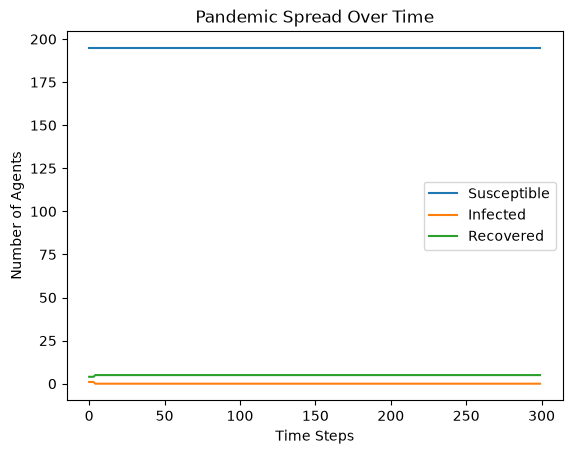

In [29]:
# Plot the number of agents in each state over time
import matplotlib.pyplot as plt

plt.plot(susceptible_counts, label='Susceptible')
plt.plot(infected_counts, label='Infected')
plt.plot(recovered_counts, label='Recovered')
plt.xlabel('Time Steps')
plt.ylabel('Number of Agents')
plt.title('Pandemic Spread Over Time')
plt.legend()
plt.show()

## Sensitivity Analysis

In [30]:
def plot_pandemic_progress(susceptible_counts, infected_counts, recovered_counts, p, q):
    plt.plot(susceptible_counts, label='Susceptible')
    plt.plot(infected_counts, label='Infected')
    plt.plot(recovered_counts, label='Recovered')
    plt.xlabel('Time Steps')
    plt.ylabel('Number of Agents')
    plt.title(f'Pandemic Spread Over Time (p={p}, q={q})')
    plt.legend()
    plt.show()

0th run for p=0.15, q=0.02


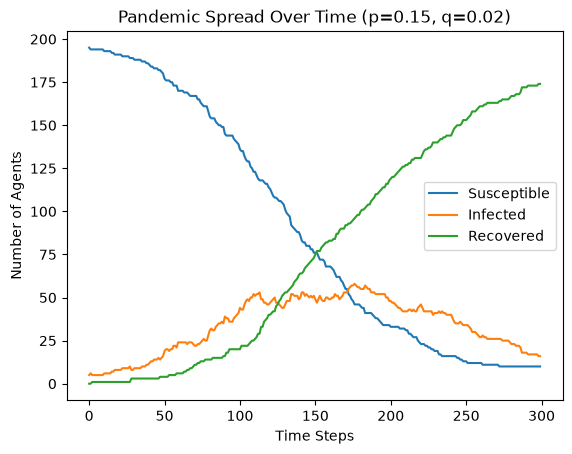

1th run for p=0.15, q=0.02


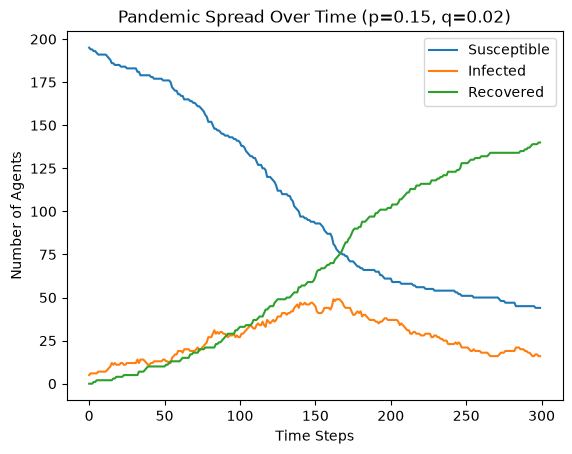

2th run for p=0.15, q=0.02


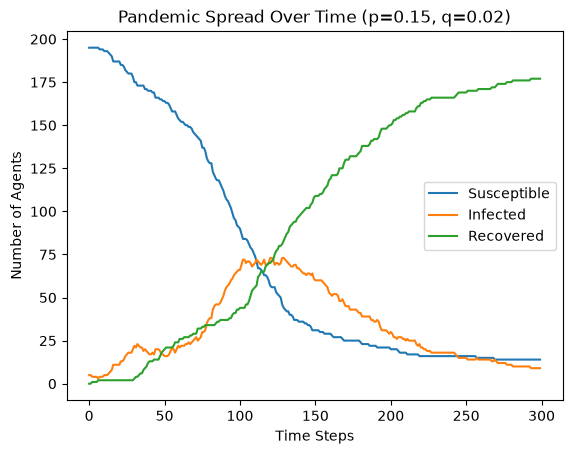

3th run for p=0.15, q=0.02


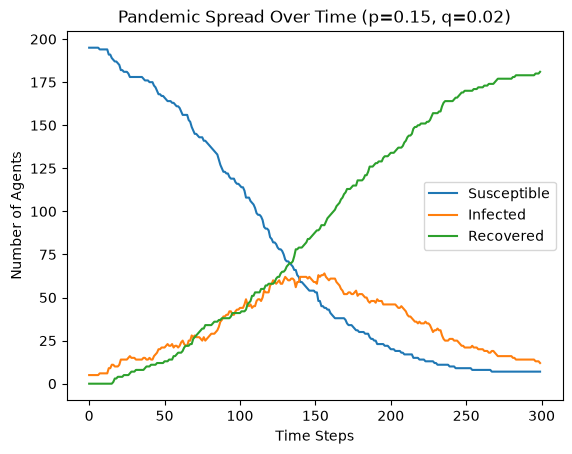

4th run for p=0.15, q=0.02


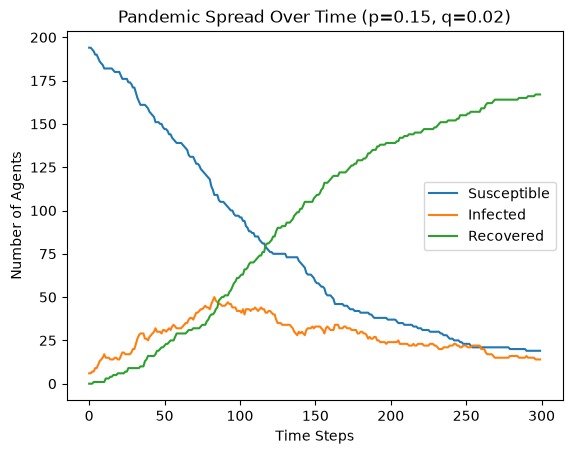

5th run for p=0.15, q=0.02


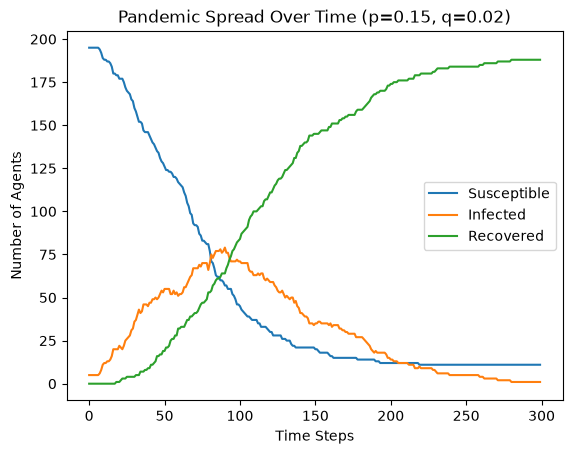

6th run for p=0.15, q=0.02


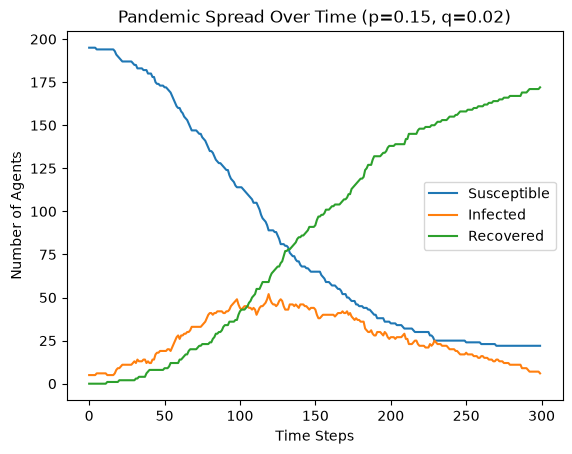

7th run for p=0.15, q=0.02


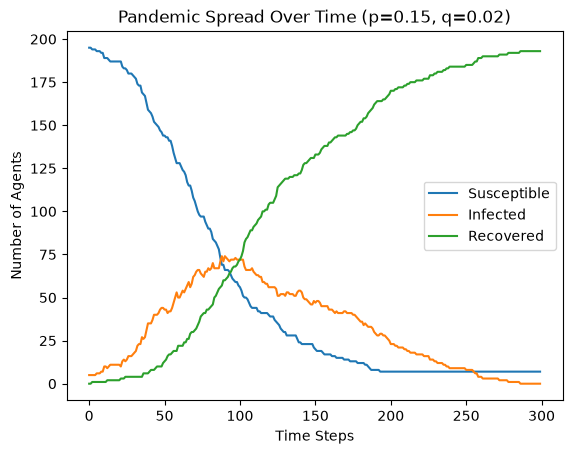

8th run for p=0.15, q=0.02


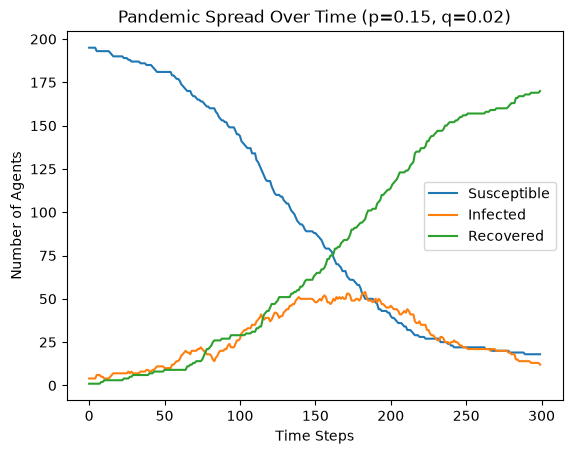

9th run for p=0.15, q=0.02


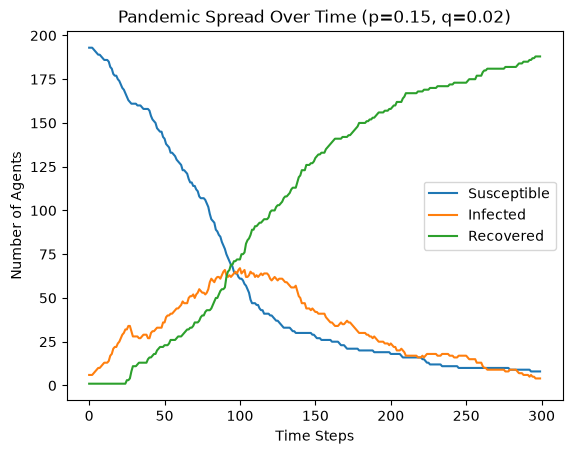

10th run for p=0.15, q=0.02


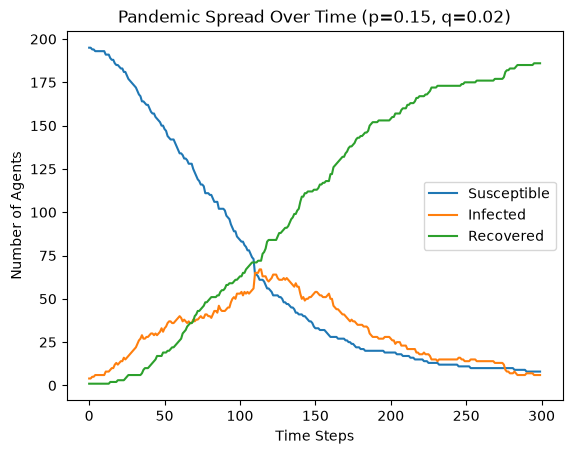

11th run for p=0.15, q=0.02


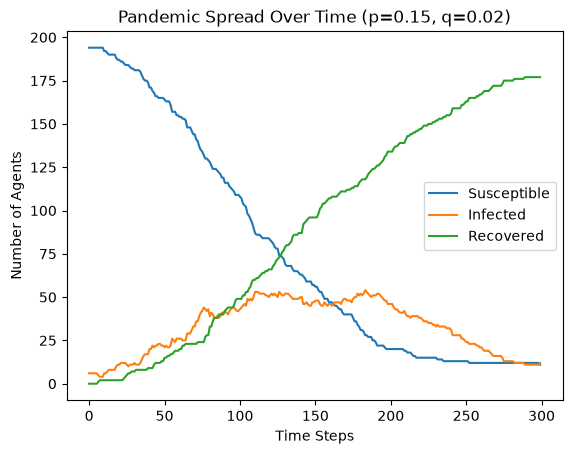

12th run for p=0.15, q=0.02


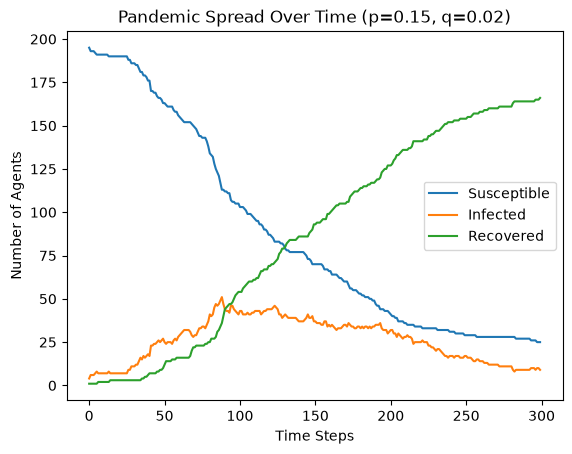

13th run for p=0.15, q=0.02


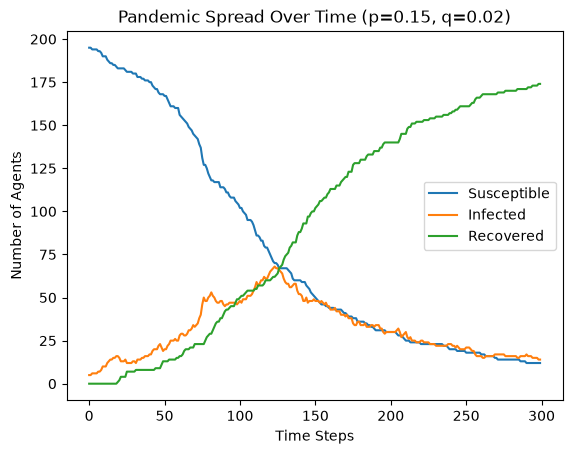

14th run for p=0.15, q=0.02


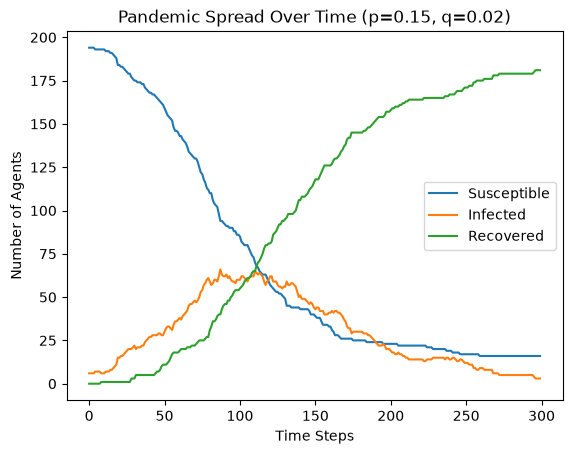

15th run for p=0.15, q=0.02


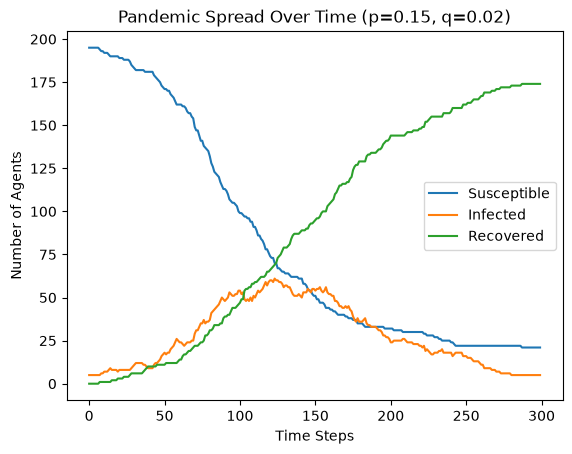

16th run for p=0.15, q=0.02


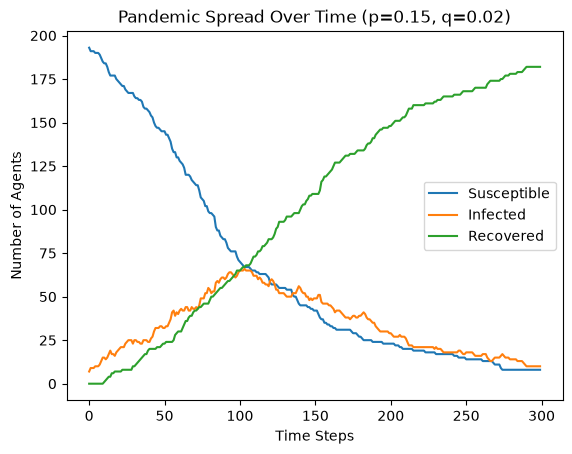

17th run for p=0.15, q=0.02


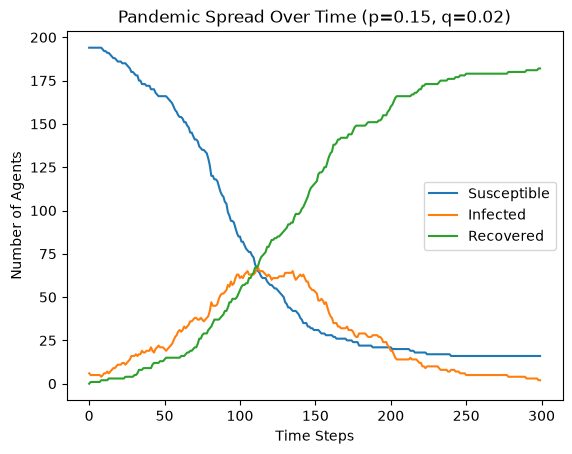

18th run for p=0.15, q=0.02


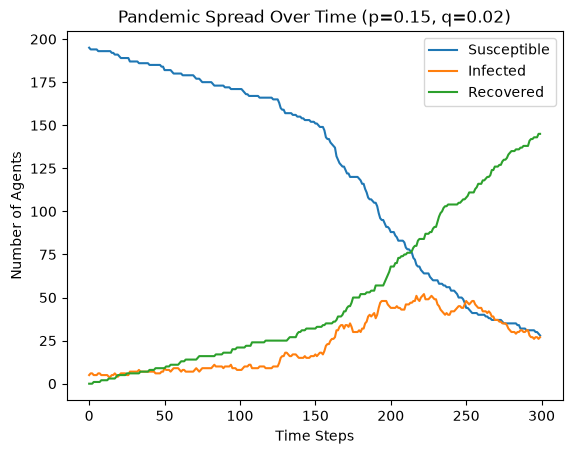

19th run for p=0.15, q=0.02


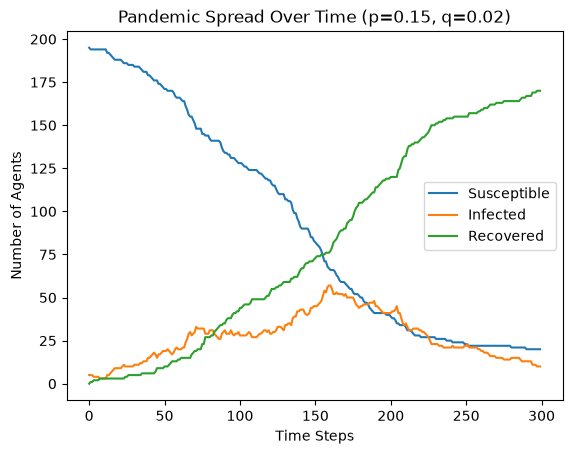

Average Runs for p=0.15, q=0.02


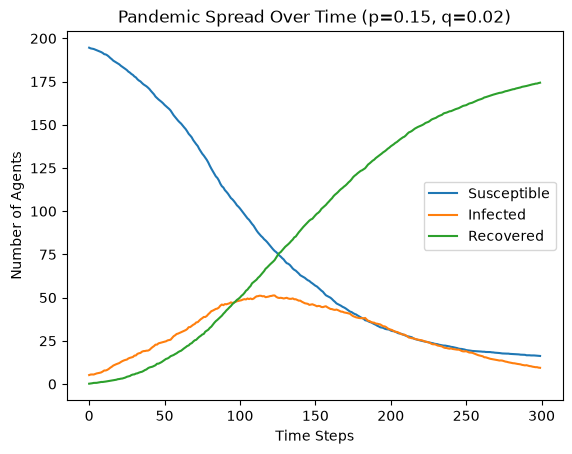

0th run for p=0.15, q=0.04


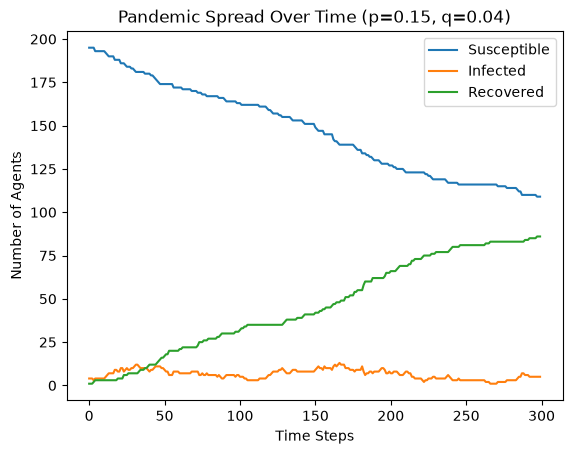

1th run for p=0.15, q=0.04


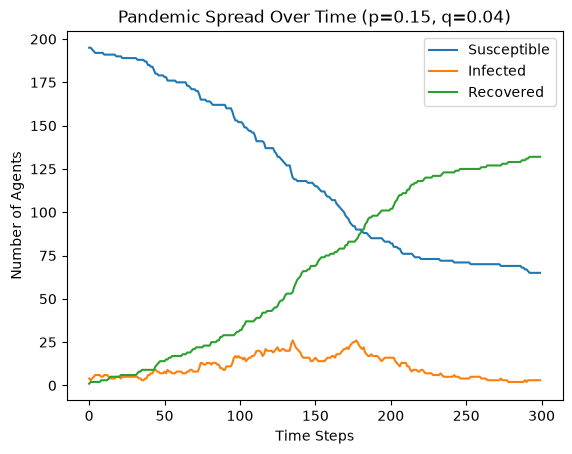

2th run for p=0.15, q=0.04


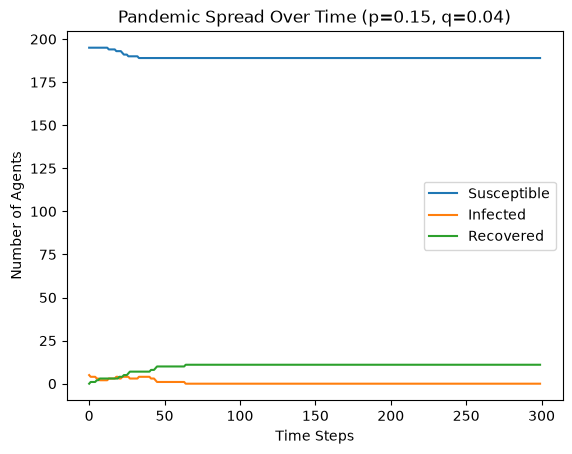

3th run for p=0.15, q=0.04


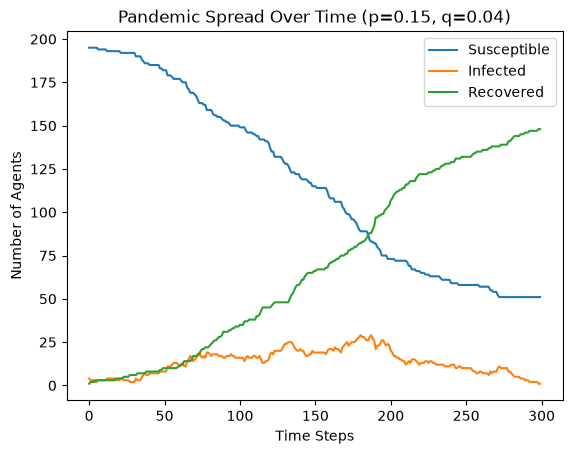

4th run for p=0.15, q=0.04


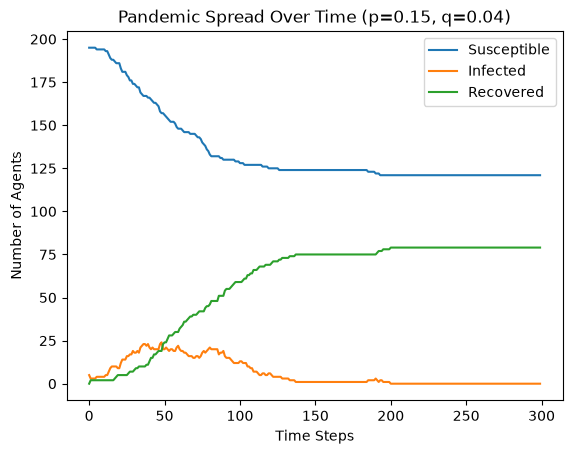

5th run for p=0.15, q=0.04


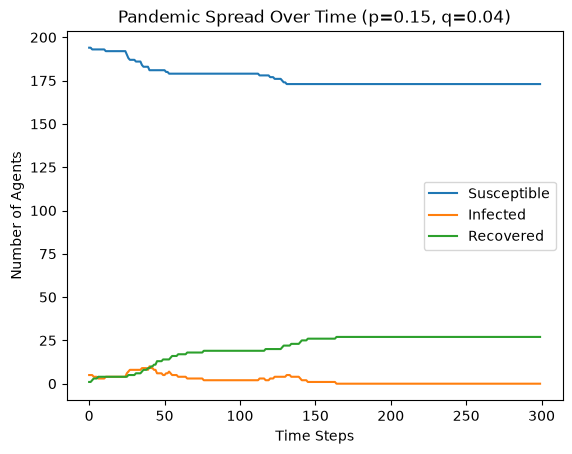

6th run for p=0.15, q=0.04


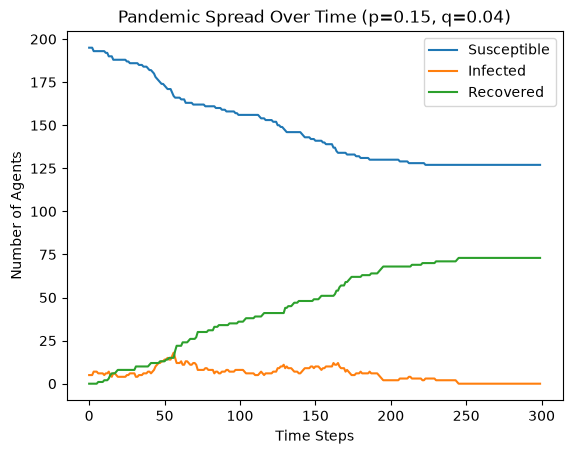

7th run for p=0.15, q=0.04


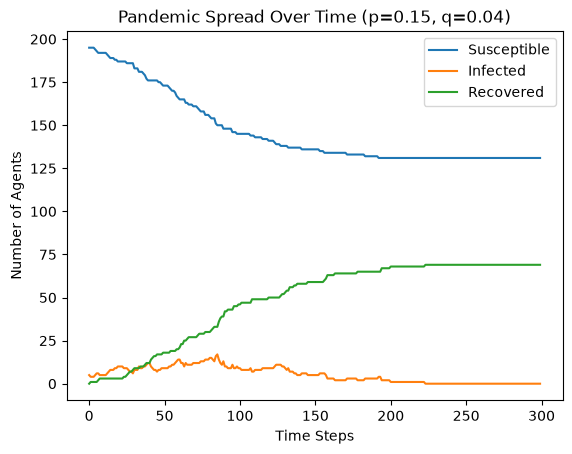

8th run for p=0.15, q=0.04


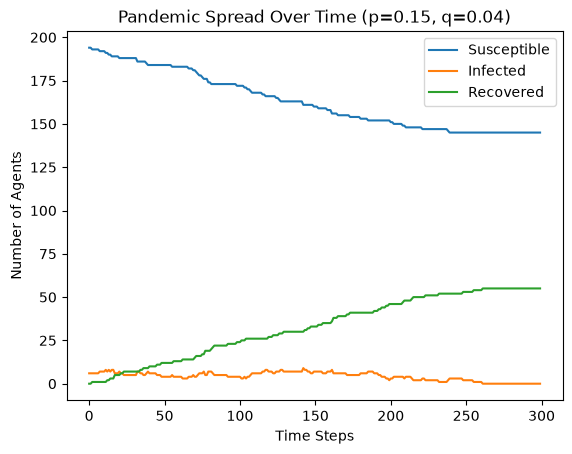

9th run for p=0.15, q=0.04


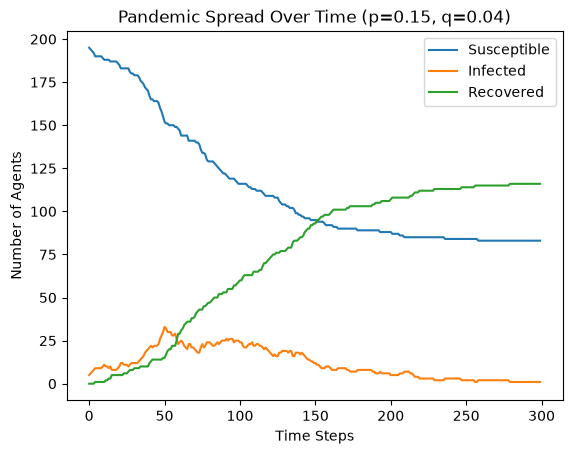

10th run for p=0.15, q=0.04


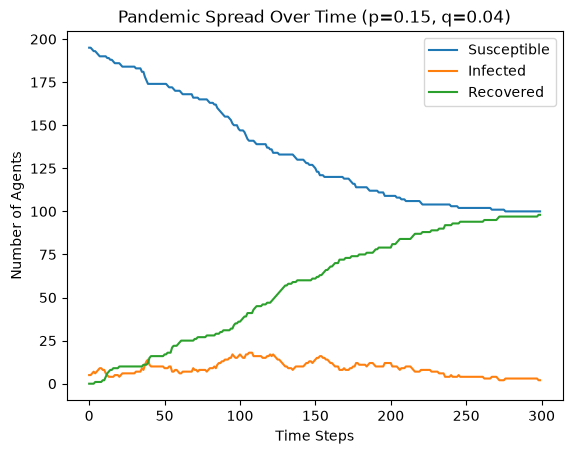

11th run for p=0.15, q=0.04


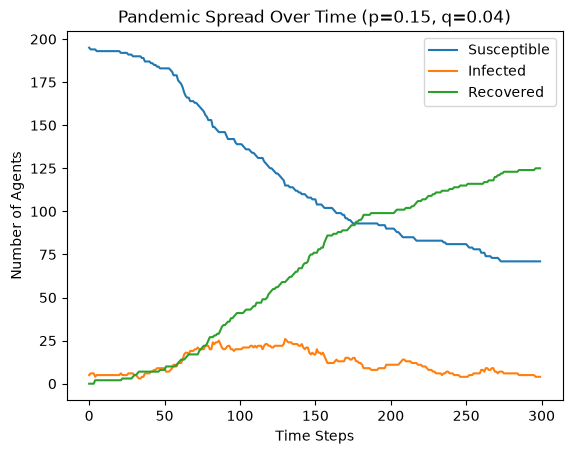

12th run for p=0.15, q=0.04


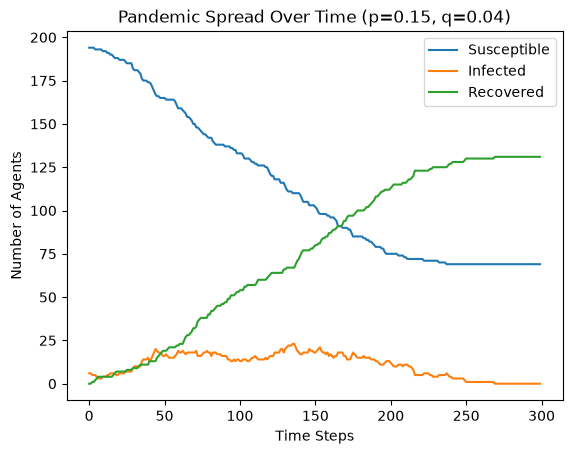

13th run for p=0.15, q=0.04


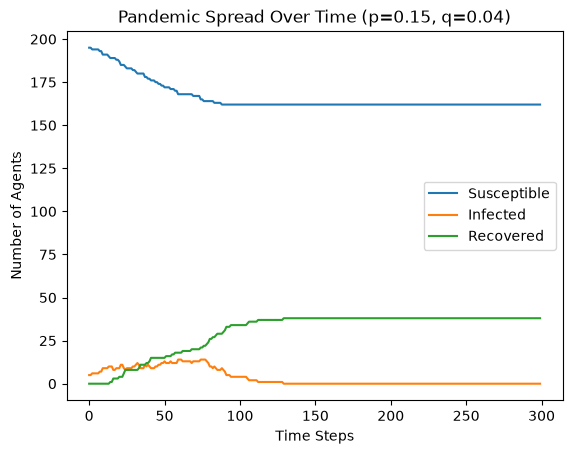

14th run for p=0.15, q=0.04


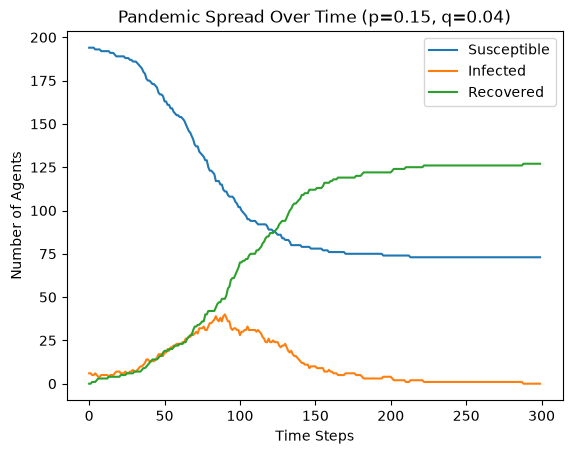

15th run for p=0.15, q=0.04


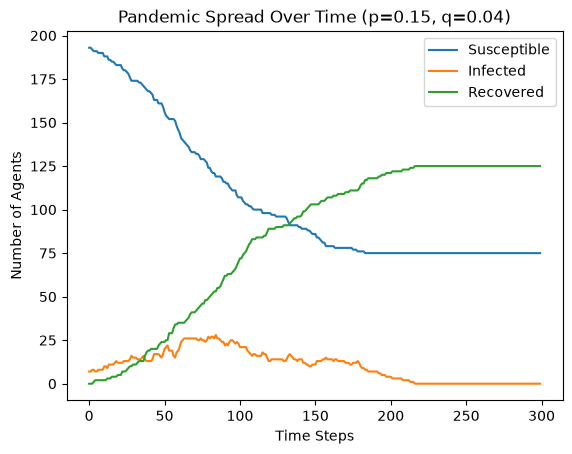

16th run for p=0.15, q=0.04


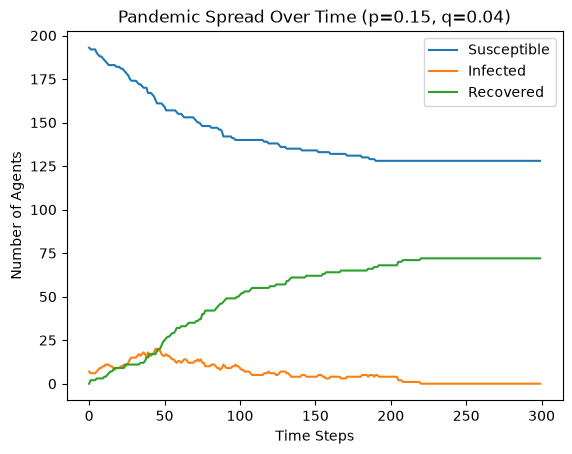

17th run for p=0.15, q=0.04


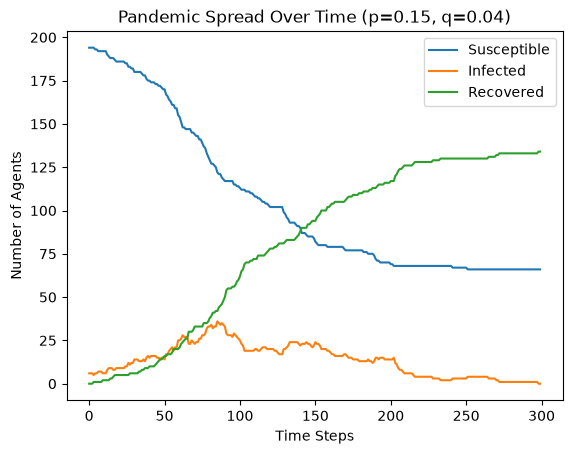

18th run for p=0.15, q=0.04


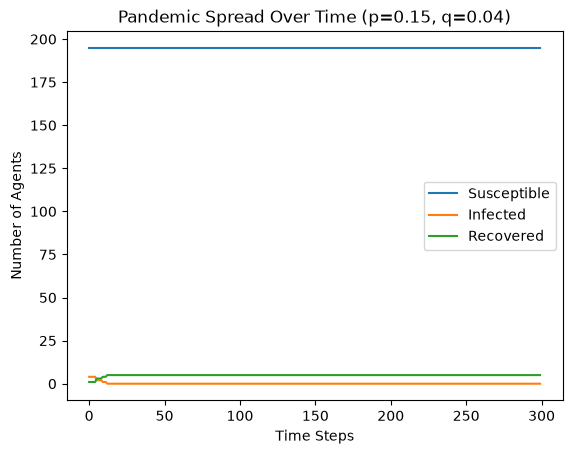

19th run for p=0.15, q=0.04


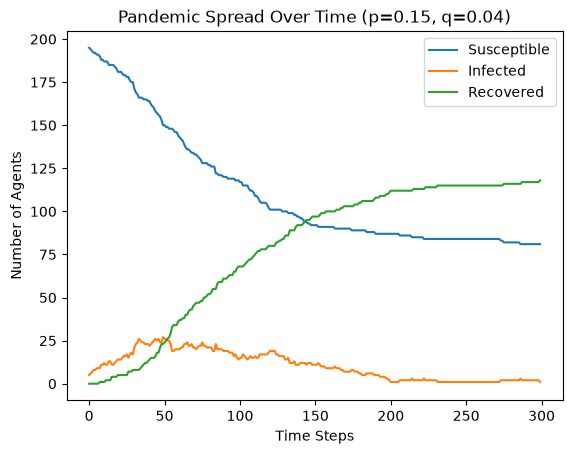

Average Runs for p=0.15, q=0.04


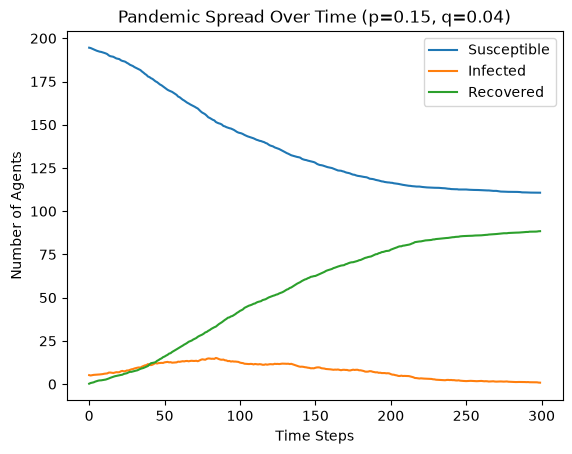

0th run for p=0.3, q=0.02


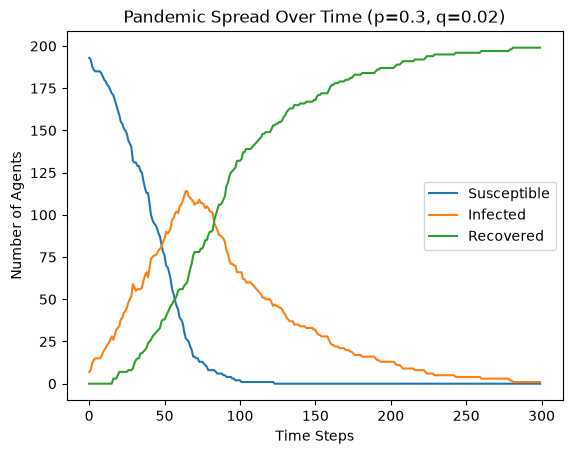

1th run for p=0.3, q=0.02


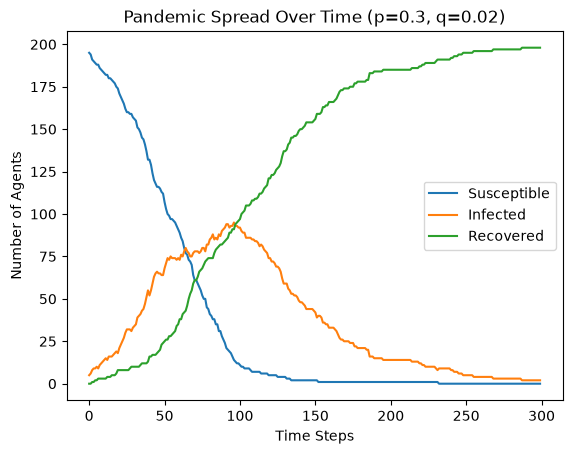

2th run for p=0.3, q=0.02


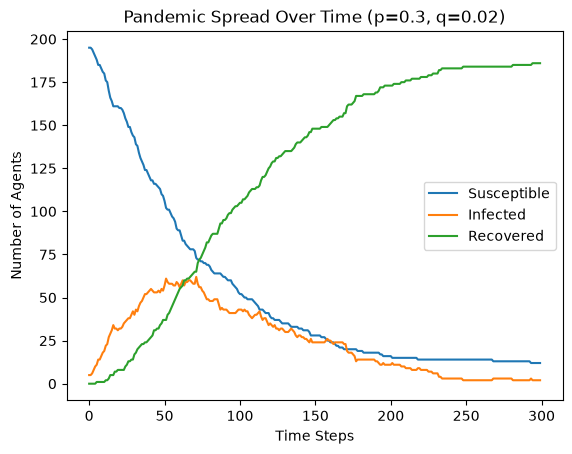

3th run for p=0.3, q=0.02


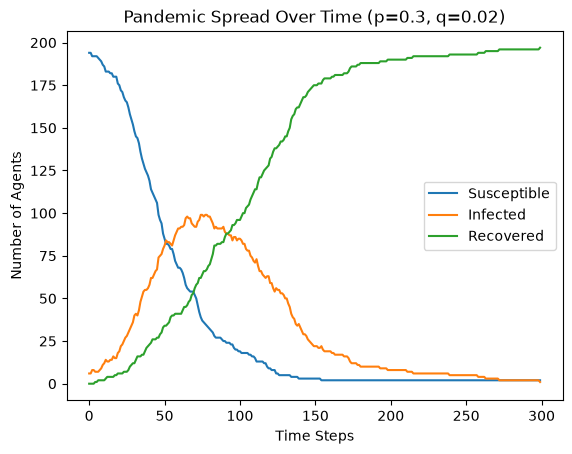

4th run for p=0.3, q=0.02


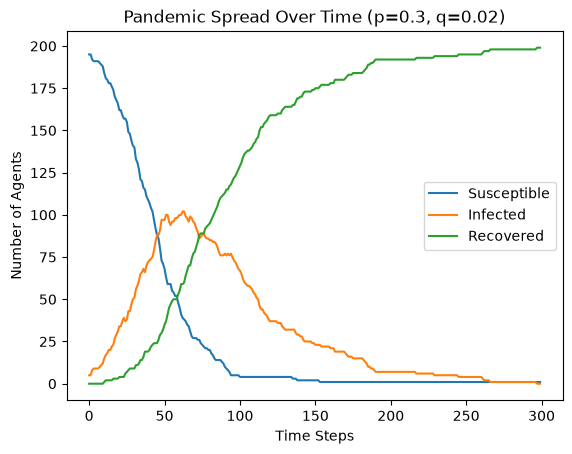

5th run for p=0.3, q=0.02


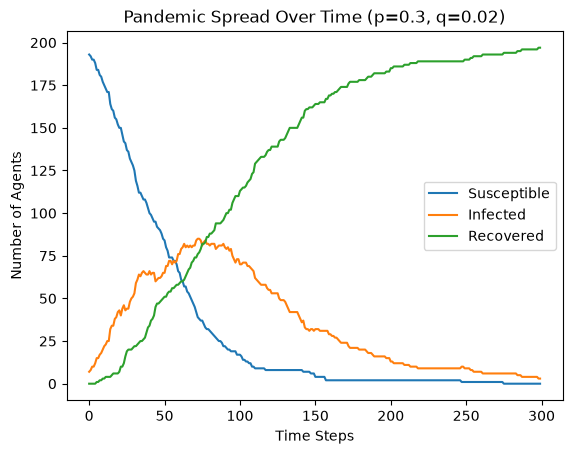

6th run for p=0.3, q=0.02


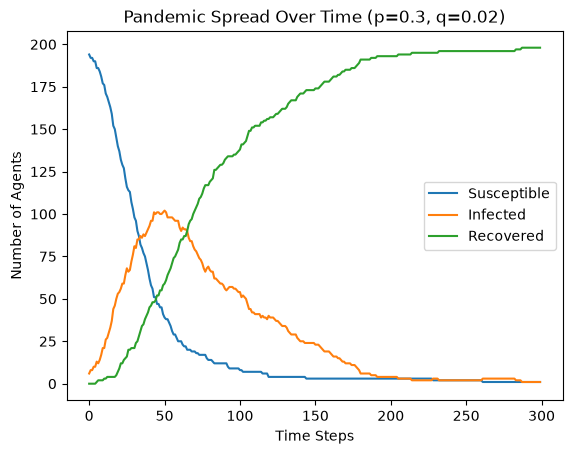

7th run for p=0.3, q=0.02


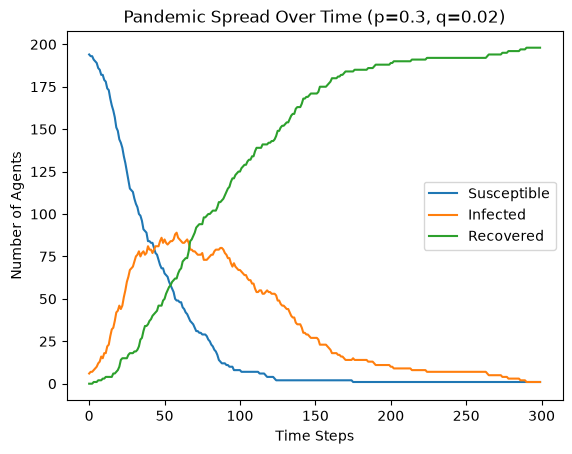

8th run for p=0.3, q=0.02


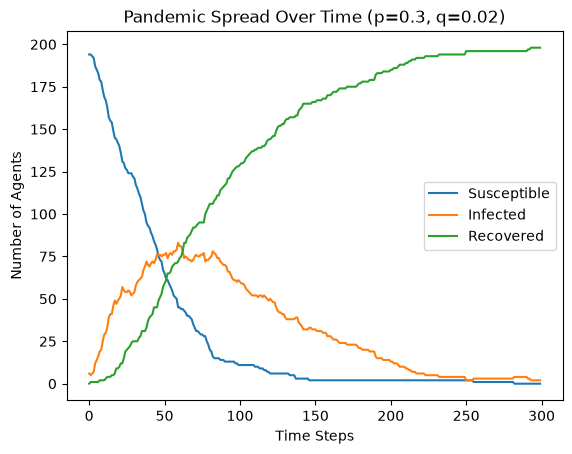

9th run for p=0.3, q=0.02


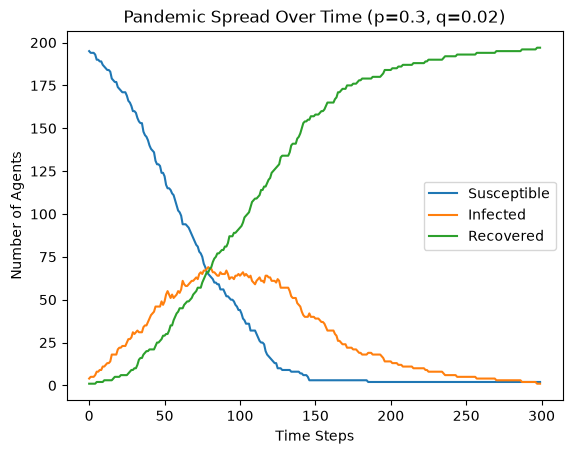

10th run for p=0.3, q=0.02


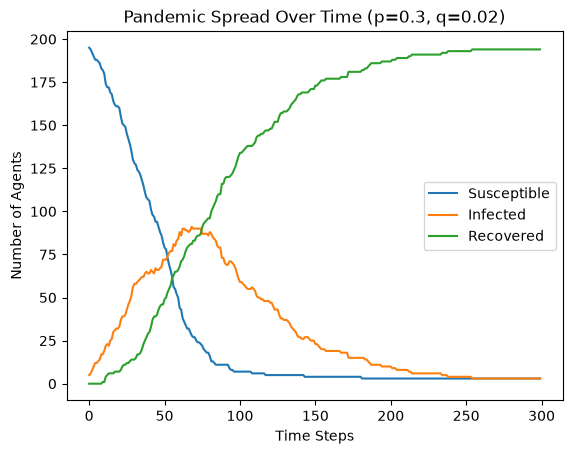

11th run for p=0.3, q=0.02


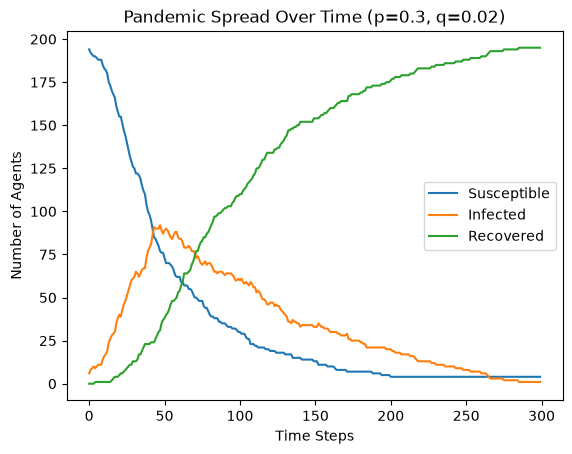

12th run for p=0.3, q=0.02


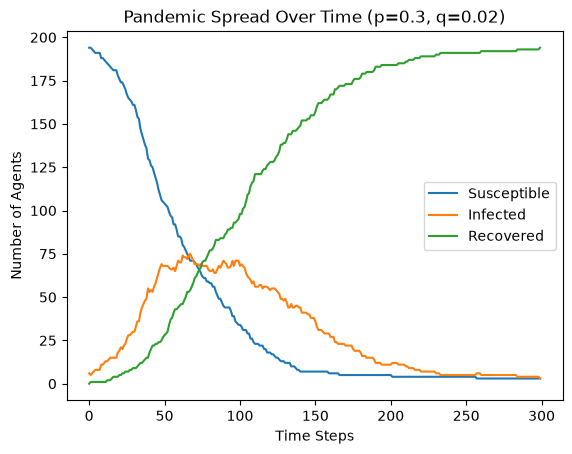

13th run for p=0.3, q=0.02


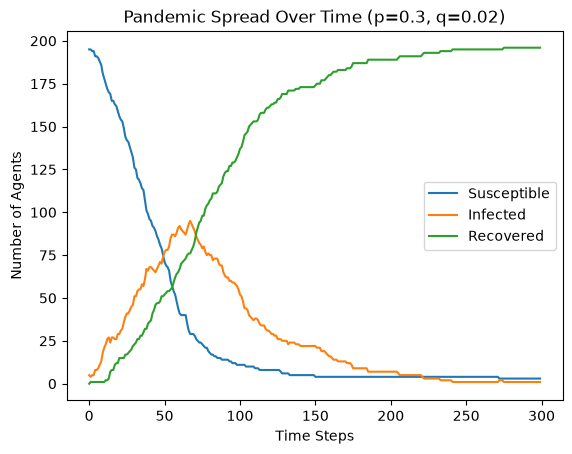

14th run for p=0.3, q=0.02


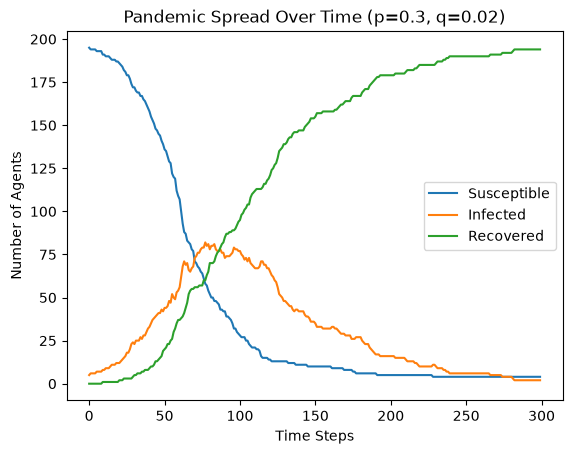

15th run for p=0.3, q=0.02


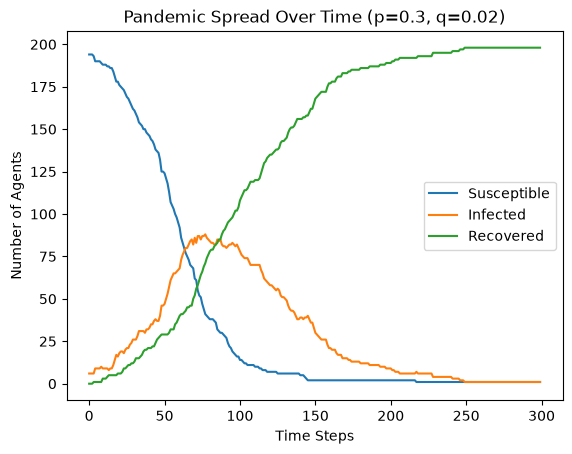

16th run for p=0.3, q=0.02


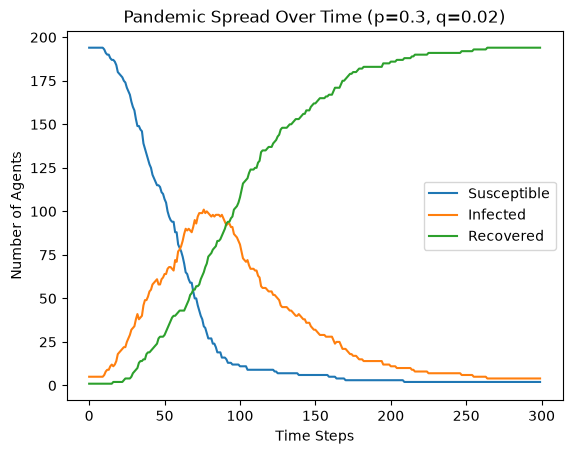

17th run for p=0.3, q=0.02


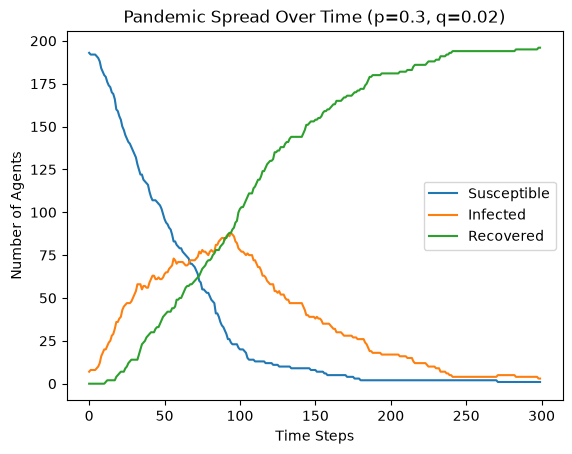

18th run for p=0.3, q=0.02


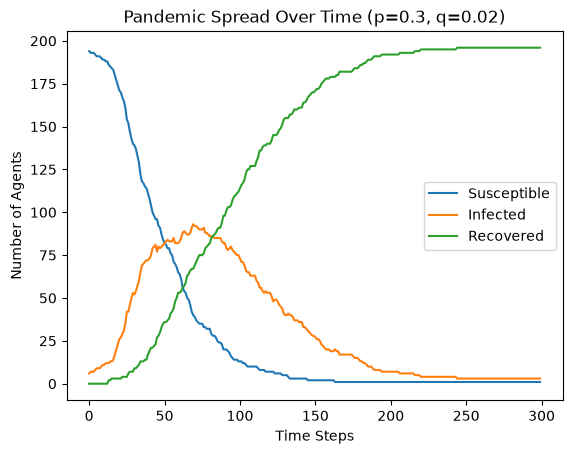

19th run for p=0.3, q=0.02


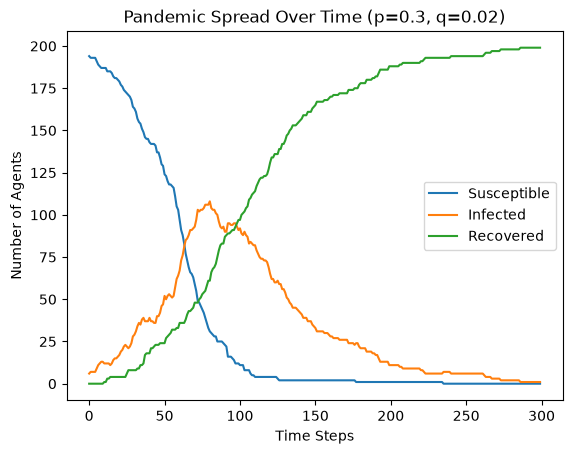

Average Runs for p=0.3, q=0.02


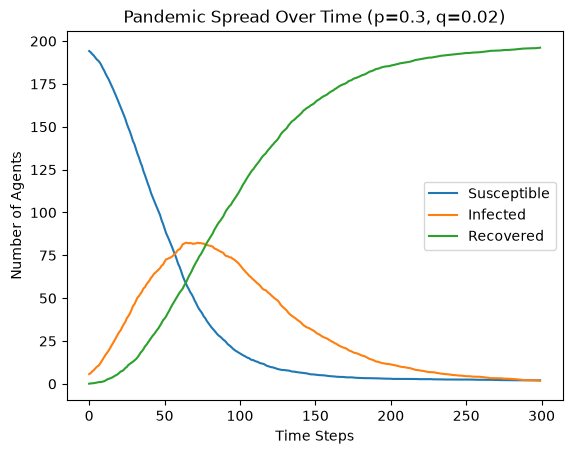

0th run for p=0.3, q=0.04


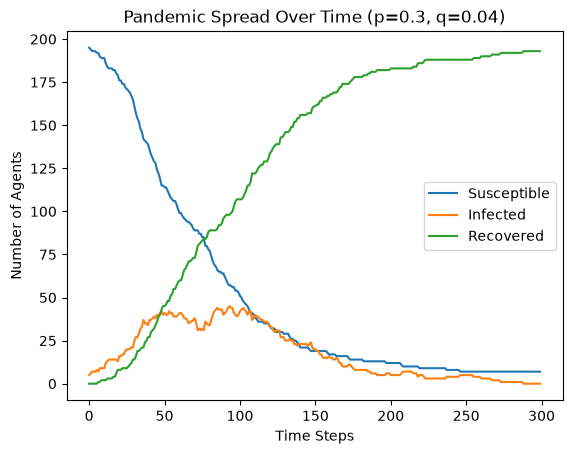

1th run for p=0.3, q=0.04


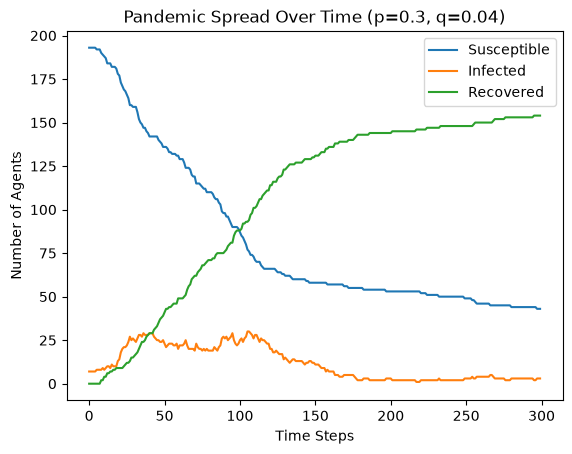

2th run for p=0.3, q=0.04


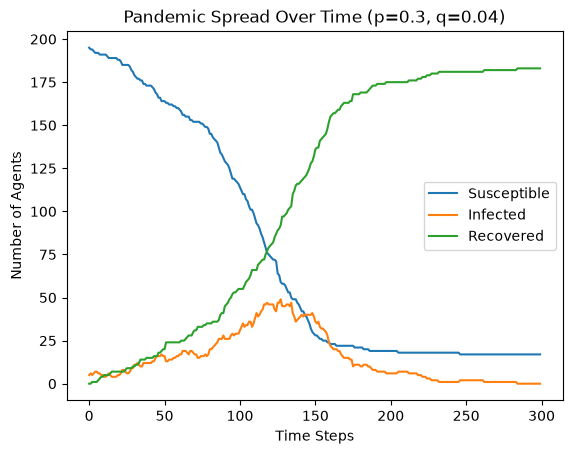

3th run for p=0.3, q=0.04


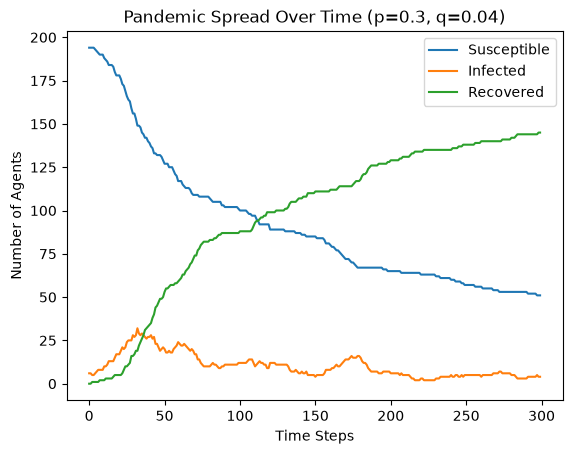

4th run for p=0.3, q=0.04


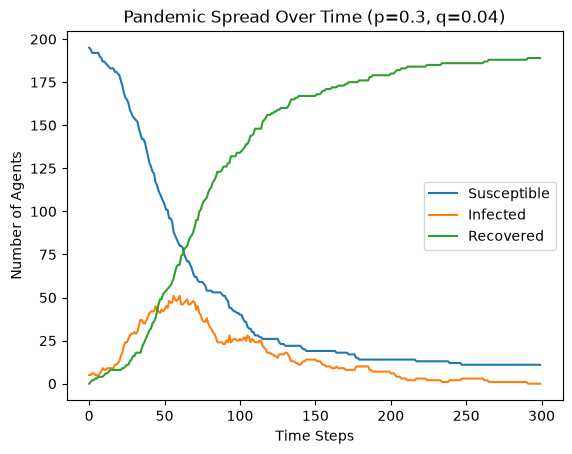

5th run for p=0.3, q=0.04


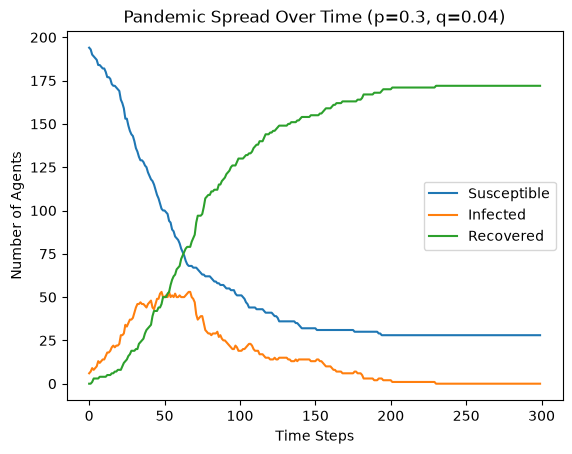

6th run for p=0.3, q=0.04


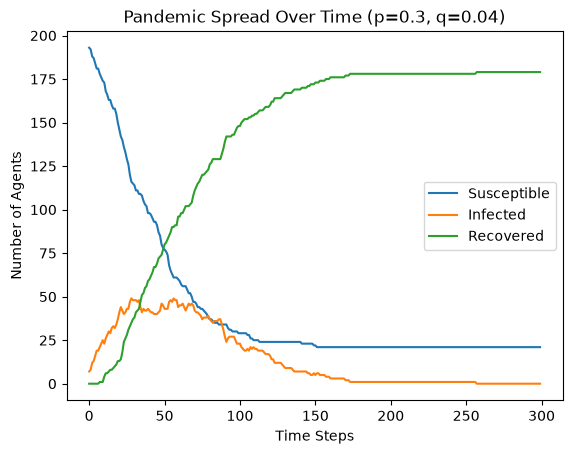

7th run for p=0.3, q=0.04


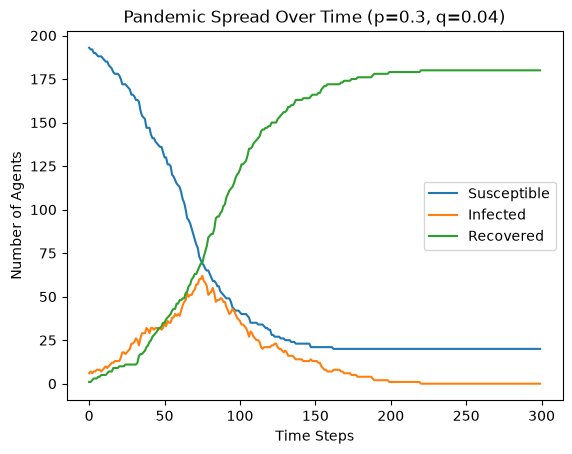

8th run for p=0.3, q=0.04


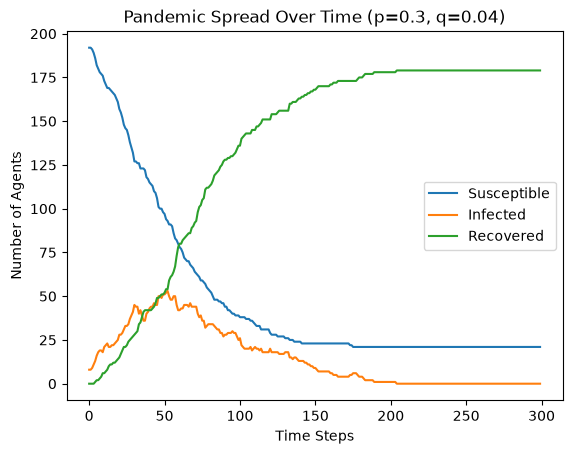

9th run for p=0.3, q=0.04


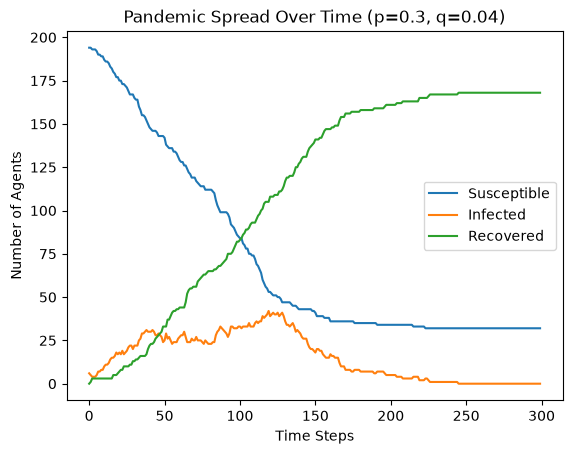

10th run for p=0.3, q=0.04


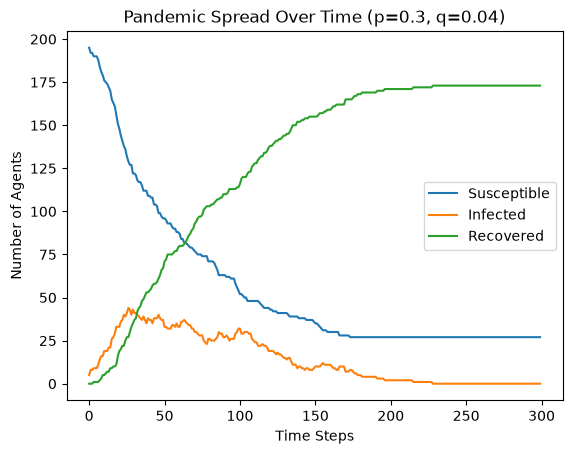

11th run for p=0.3, q=0.04


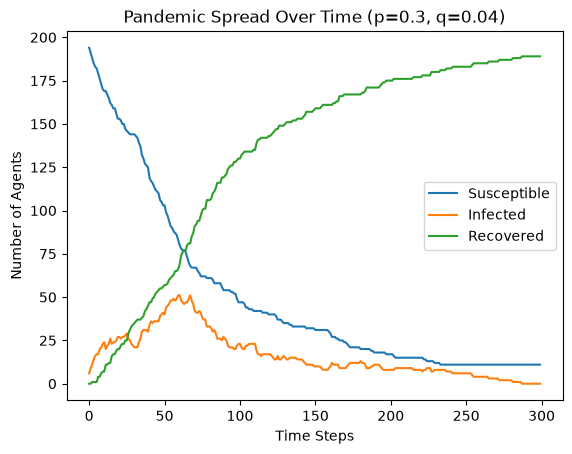

12th run for p=0.3, q=0.04


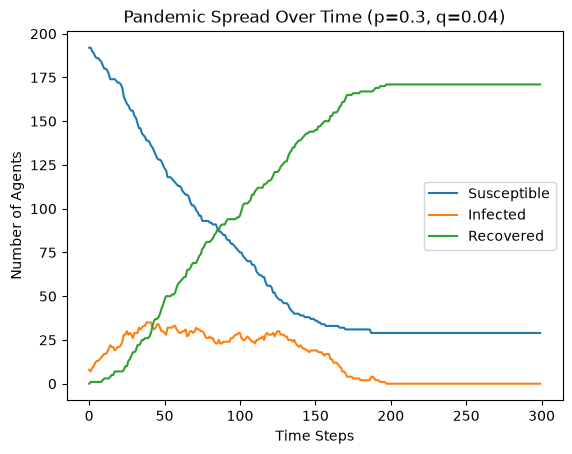

13th run for p=0.3, q=0.04


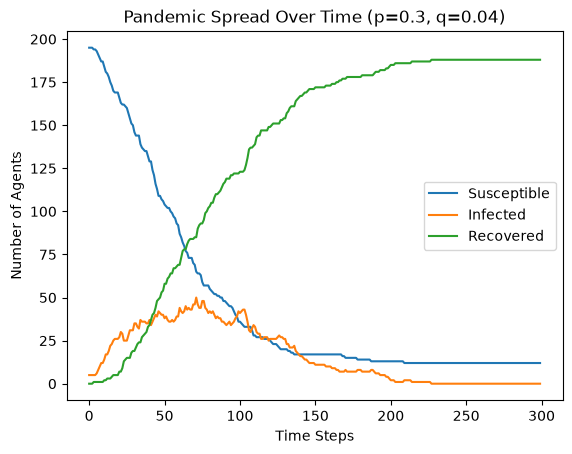

14th run for p=0.3, q=0.04


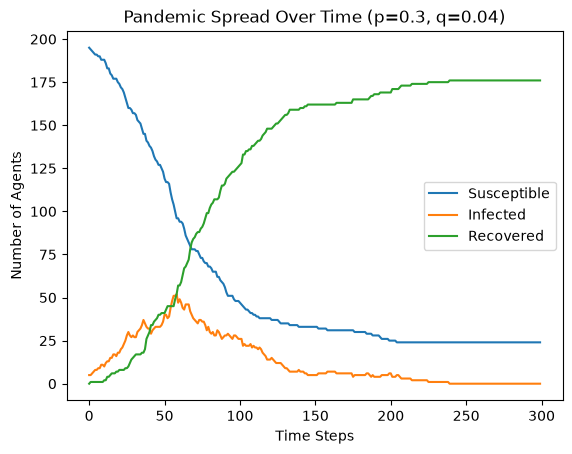

15th run for p=0.3, q=0.04


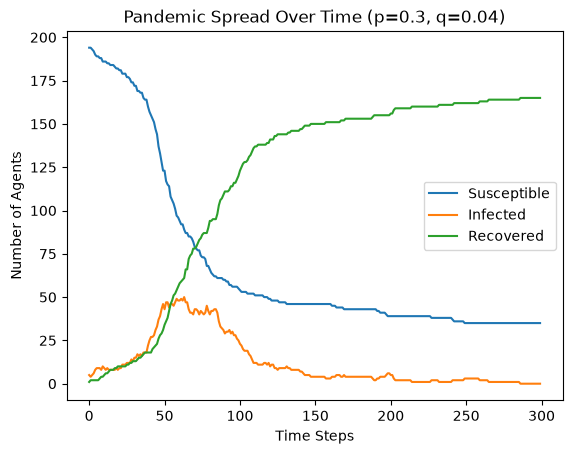

16th run for p=0.3, q=0.04


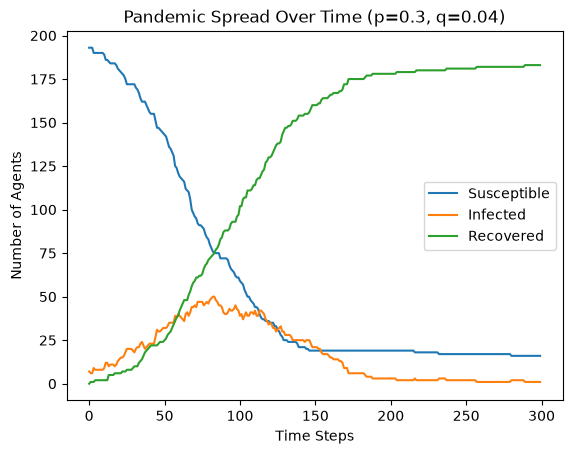

17th run for p=0.3, q=0.04


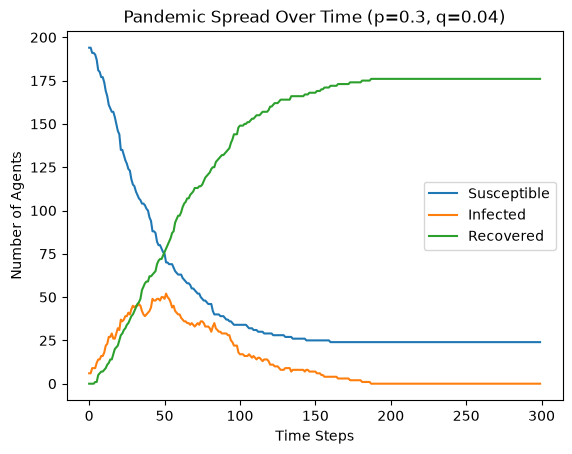

18th run for p=0.3, q=0.04


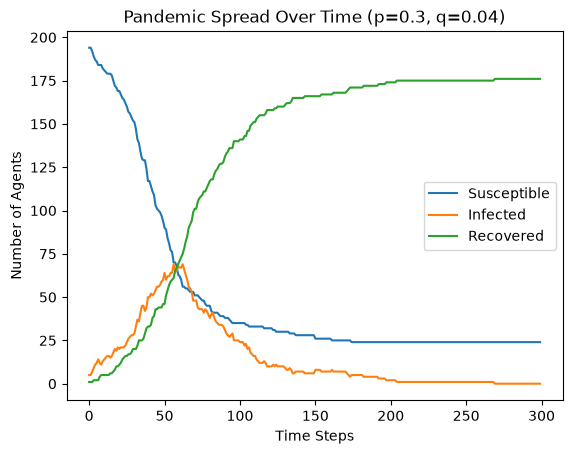

19th run for p=0.3, q=0.04


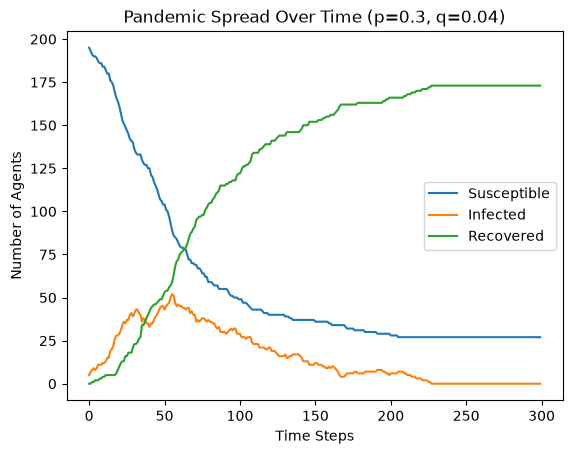

Average Runs for p=0.3, q=0.04


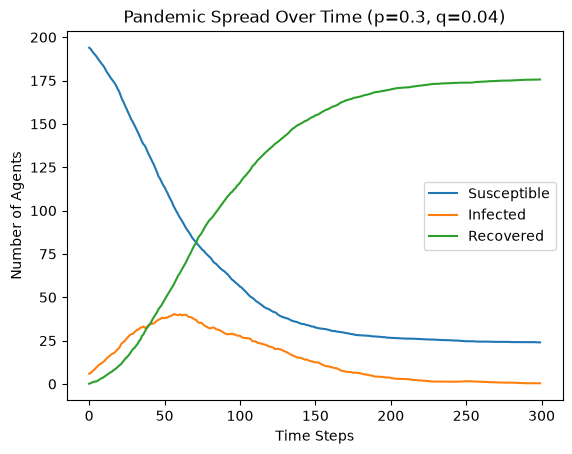

In [63]:
for p in [0.15, 0.3]:
    for q in [0.02, 0.04]:
        avrage_susceptible_counts = []
        avrage_infected_counts = []
        avrage_recovered_counts = []
        for n in range(20): # For each combination, run at least 20 simulations with different random initial positions
            agents = initialize_agent_grid(grid_size=20, num_susceptible=195, num_infected=5, num_recovered=0)
            susceptible_counts, infected_counts, recovered_counts = simulate_pandemic(agents, q, p, 300)

            # Plot the individual runs
            print(f"{n}th run for p={p}, q={q}")
            plot_pandemic_progress(susceptible_counts, infected_counts, recovered_counts, p, q)
            
            avrage_susceptible_counts.append(susceptible_counts)
            avrage_infected_counts.append(infected_counts)
            avrage_recovered_counts.append(recovered_counts)

        # Calculate the average counts over all simulations
        avg_susceptible = np.mean(avrage_susceptible_counts, axis=0)
        avg_infected = np.mean(avrage_infected_counts, axis=0)
        avg_recovered = np.mean(avrage_recovered_counts, axis=0)

        # Plot the average counts
        print(f"Average Runs for p={p}, q={q}")
        plot_pandemic_progress(avg_susceptible, avg_infected, avg_recovered, p, q)

#### How much do individual runs differ from the average?

The individual runs overall are similar to the average across the 20 runs. However, when p=0.15 and q=0.04, the individual runs do differ quite visibly. Depending on the random initialization, we would sometimes see the number of recovered people greater than the number of suceptible people and, other times, see the reverse of that. 

#### In how many runs does the outbreak die out early?

In 4 runs (3, 6, 14, 19), the number of recovered people plateaued below 50, effectively showing that the pandemic infected than 25% of the population. 2 of the 4 runs did not show any increase in the number of recovered people nor the peak in the number of infected individuals, demonstrating that the outbreak potentially did not occur despite the presence of infected individiduals. 

## Extending the Model: Social Distancing and Interventions

### Introduce social distancing measures
with p = 0.3 and q = 0.02

### [Reduced Movement] Which part of the model do you change to implement this?

It should be incorporated into the move function of the Agent2 class. The if condition is added to ensure that the agent moves probabilistically based on the value of m.

### [Avoidance] Which part of the model do you change to implement this? 

It should be incorporated into the move_and_avoid function of the Agent2 class. First, the if statement is used to determine whether the agent is susceptible or infected/recovered. If not susceptible, the agent would move without considering avoidance. If the agent is susceptible, it would move to the safe location, if available.

In [52]:
class Agent2:
    def __init__(self, x, y, status="susceptible"):
        self.x = x
        self.y = y
        self.status = status

    movement = dict({"up": (-1, 0), "down": (1, 0), "left": (0, -1), "right": (0, 1), "stay": (0, 0)})

    # Reduce the movement by imposing the probability m
    def move(self, direction, m):
        if np.random.rand() < m:
            if direction in Agent2.movement:
                dx, dy = Agent2.movement[direction]
                self.x = max(0, min(19, self.x + dx))
                self.y = max(0, min(19, self.y + dy))

    # Enable avoidance (when moving, susceptible agents can move away from cells occupied by infected agents)
    def move_and_avoid(self, infected_cells, m):
        # If the agent is not susceptible, move randomly with probability m
        if self.is_susceptible() is False:
            self.move(np.random.choice(list(Agent2.movement.keys())), m)
        # If the agent is susceptible, try to move to a safe cell away from infected cells
        # The agent will move randomly if:
        #       (1) all cells (top, bottom, left, right) are either infected or out of bounds, 
        #       (2) the agent does not have any nearby cell occupied by infected agents
        else:
            safe = []
            for direction, (dx, dy) in Agent2.movement.items():
                if (dx, dy) == (0, 0):
                    continue
                nx = max(0, min(19, self.x + dx))
                ny = max(0, min(19, self.y + dy))
                if (nx, ny) not in infected_cells:
                    safe.append(direction)
            if len(safe) > 0 and len(safe) < 4:
                self.move(np.random.choice(safe), m=1.0)
            # If there are no safe cells or all cells are safe, move randomly
            elif len(safe) == 0 or len(safe) == 4:
                self.move(np.random.choice(list(Agent2.movement.keys())), m)
            
    def infect(self, p):
        if np.random.rand() < p:
            self.status = "infected"

    def recover(self, q):
        if np.random.rand() < q:
            self.status = "recovered"

    def is_susceptible(self):
        return self.status == "susceptible"

    def is_infected(self):
        return self.status == "infected"

    def is_recovered(self):
        return self.status == "recovered"

In [53]:
def initialize_agent2_grid(grid_size, num_susceptible, num_infected, num_recovered):
    agents = []
    for _ in range(num_susceptible):
        x, y = np.random.randint(0, grid_size-1), np.random.randint(0, grid_size-1)
        agents.append(Agent2(x, y, 'susceptible'))
    for _ in range(num_infected):
        x, y = np.random.randint(0, grid_size-1), np.random.randint(0, grid_size-1)
        agents.append(Agent2(x, y, 'infected'))
    for _ in range(num_recovered):
        x, y = np.random.randint(0, grid_size-1), np.random.randint(0, grid_size-1)
        agents.append(Agent2(x, y, 'recovered'))
    return agents

In [54]:
agents2 = initialize_agent2_grid(grid_size=20, num_susceptible=195, num_infected=5, num_recovered=0)

In [58]:
def simulate_pandemic2(agents2, q, p, m, avoid=True, time_steps=300):
    susceptible_counts = []
    infected_counts = []
    recovered_counts = []

    for _ in range(time_steps):
        infected_cells = [(agent.x, agent.y) for agent in agents2 if agent.is_infected()]
        for agent in agents2:
            if avoid:
                agent.move_and_avoid(infected_cells, m)
            else:
                agent.move(np.random.choice(list(Agent2.movement.keys())), m)

        for x in range(20):
            for y in range(20):
                cell_agents = [agent for agent in agents2 if agent.x == x and agent.y == y]
                if any(agent.is_infected() for agent in cell_agents):
                    for agent in cell_agents:
                        if agent.is_infected():
                            agent.recover(q=q)
                    for agent in cell_agents:
                        if agent.is_susceptible():
                            agent.infect(p=p)

        num_susceptible = sum(agent.is_susceptible() for agent in agents2)
        num_infected = sum(agent.is_infected() for agent in agents2)
        num_recovered = sum(agent.is_recovered() for agent in agents2)

        susceptible_counts.append(num_susceptible)
        infected_counts.append(num_infected)
        recovered_counts.append(num_recovered)

    return susceptible_counts, infected_counts, recovered_counts

In [59]:
def plot_pandemic_progress2(susceptible_counts, infected_counts, recovered_counts, p, q, m):
    plt.plot(susceptible_counts, label='Susceptible')
    plt.plot(infected_counts, label='Infected')
    plt.plot(recovered_counts, label='Recovered')
    plt.xlabel('Time Steps')
    plt.ylabel('Number of Agents')
    plt.title(f'Pandemic Spread Over Time (p={p}, q={q}, m={m})')
    plt.legend()
    plt.show()

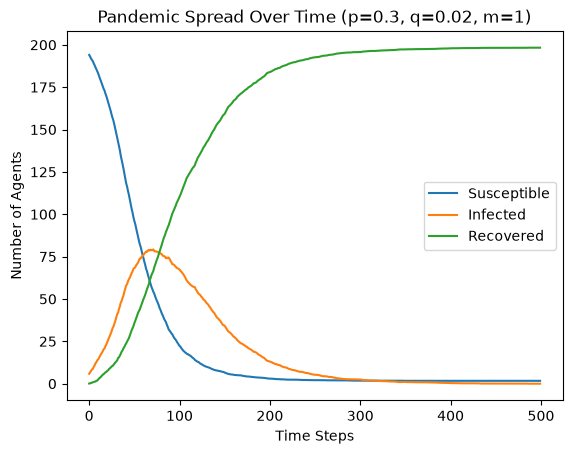

Completed simulation for avoid=False, p=0.3, q=0.02, m=1


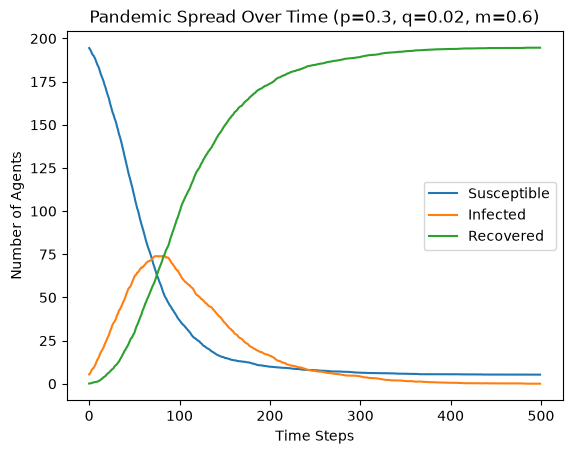

Completed simulation for avoid=False, p=0.3, q=0.02, m=0.6


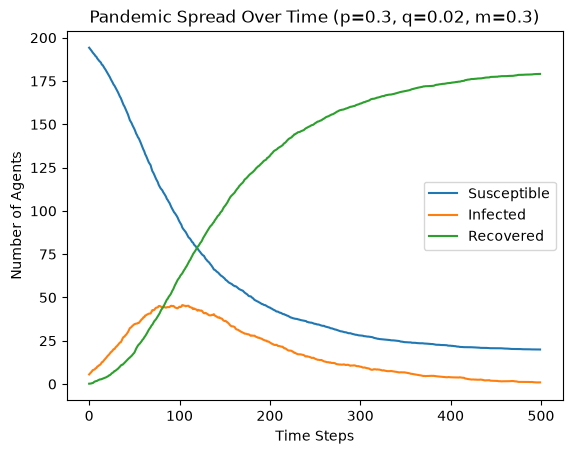

Completed simulation for avoid=False, p=0.3, q=0.02, m=0.3


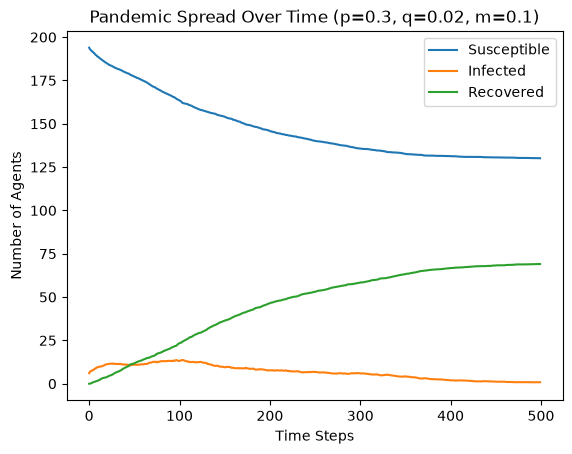

Completed simulation for avoid=False, p=0.3, q=0.02, m=0.1


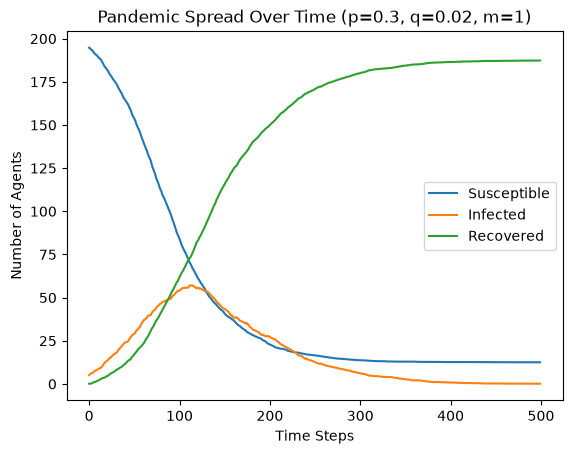

Completed simulation for avoid=True, p=0.3, q=0.02, m=1


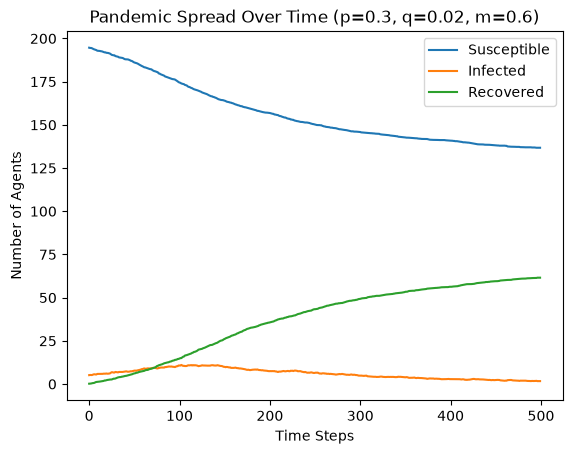

Completed simulation for avoid=True, p=0.3, q=0.02, m=0.6


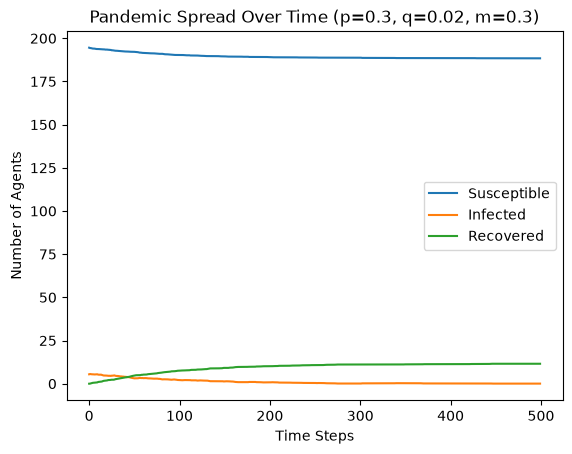

Completed simulation for avoid=True, p=0.3, q=0.02, m=0.3


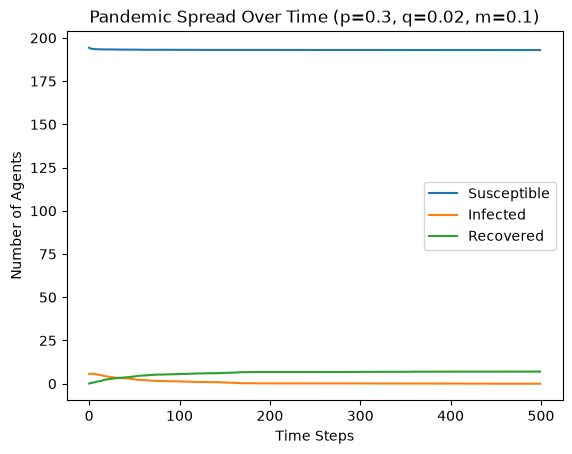

Completed simulation for avoid=True, p=0.3, q=0.02, m=0.1


In [70]:
average_susceptible_counts_dict = {}
average_infected_counts_dict = {}
average_recovered_counts_dict = {}

for avoid in [False, True]:
    for p in [0.3]:
        for q in [0.02]:
            for m in [1, 0.6, 0.3, 0.1]:
                #generate a key for avoid and m
                key = (avoid, m)
                average_susceptible_counts_dict[key] = []
                average_infected_counts_dict[key] = []
                average_recovered_counts_dict[key] = []
                for _ in range(20): # For each combination, run at least 20 simulations with different random initial positions
                    agents2 = initialize_agent2_grid(grid_size=20, num_susceptible=195, num_infected=5, num_recovered=0)
                    susceptible_counts, infected_counts, recovered_counts = simulate_pandemic2(agents2, q, p, m, avoid=avoid, time_steps=500)

                    # Plot the individual runs
                    #plot_pandemic_progress2(susceptible_counts, infected_counts, recovered_counts, p, q, m)
                    
                    average_susceptible_counts_dict[key].append(susceptible_counts)
                    average_infected_counts_dict[key].append(infected_counts)
                    average_recovered_counts_dict[key].append(recovered_counts)

                # Calculate the average counts over all simulations
                avg_susceptible = np.mean(average_susceptible_counts_dict[key], axis=0)
                avg_infected = np.mean(average_infected_counts_dict[key], axis=0)
                avg_recovered = np.mean(average_recovered_counts_dict[key], axis=0)

                # Plot the average counts
                plot_pandemic_progress2(avg_susceptible, avg_infected, avg_recovered, p, q, m)

                print(f"Completed simulation for avoid={avoid}, p={p}, q={q}, m={m}")


### Which parameter controls the maximum number of simultaneously infected agents?

It seems that both the reduced movement is the more important factor. The difference between m=1 and 0.01 is greater than the difference between when the agents starts avoiding or not.

### Compare the results with and without social distancing
Set avoid=True vs avoid=False

In [71]:
# The peak number of infected agents
peak_infected_no_distancing = []
peak_infected_distancing = []

for key in average_susceptible_counts_dict:
    avg_susceptible = np.mean(average_susceptible_counts_dict[key], axis=0)
    avg_infected = np.mean(average_infected_counts_dict[key], axis=0)
    avg_recovered = np.mean(average_recovered_counts_dict[key], axis=0)
    if key[0] == False: # no social distancing peak number of infected agents:
        peak_infected_no_distancing.append(np.max(avg_infected))

    else:
        peak_infected_distancing.append(np.max(avg_infected))

print("Peak infected without social distancing:", peak_infected_no_distancing)
print("Peak infected with social distancing:", peak_infected_distancing)

Peak infected without social distancing: [np.float64(79.25), np.float64(74.0), np.float64(45.6), np.float64(13.65)]
Peak infected with social distancing: [np.float64(57.2), np.float64(11.05), np.float64(5.6), np.float64(5.8)]


In [72]:
# The time to the peak, and the time until no infected agents remain
time_to_no_infected_no_distancing = []
time_to_no_infected_distancing = []
time_to_peak_no_distancing = []
time_to_peak_distancing = []

for key in average_susceptible_counts_dict:
    avg_susceptible = np.mean(average_susceptible_counts_dict[key], axis=0)
    avg_infected = np.mean(average_infected_counts_dict[key], axis=0)
    avg_recovered = np.mean(average_recovered_counts_dict[key], axis=0)
    if key[0] == False: # no social distancing peak number of infected agents:
        time_to_no_infected_no_distancing.append(np.argmax(avg_infected == 0))
        time_to_peak_no_distancing.append(np.argmax(avg_infected))

    else:
        time_to_no_infected_distancing.append(np.argmax(avg_infected == 0))
        time_to_peak_distancing.append(np.argmax(avg_infected))

print("Time to no infected without social distancing:", time_to_no_infected_no_distancing)
print("Time to no infected with social distancing:", time_to_no_infected_distancing)
print("Time to peak without social distancing:", time_to_peak_no_distancing)
print("Time to peak with social distancing:", time_to_peak_distancing)

Time to no infected without social distancing: [np.int64(485), np.int64(0), np.int64(0), np.int64(0)]
Time to no infected with social distancing: [np.int64(0), np.int64(0), np.int64(0), np.int64(443)]
Time to peak without social distancing: [np.int64(71), np.int64(83), np.int64(103), np.int64(103)]
Time to peak with social distancing: [np.int64(114), np.int64(102), np.int64(1), np.int64(2)]


In [73]:
# The total number of agents ever infected
total_infected_no_distancing = []
total_infected_distancing = []

for key in average_susceptible_counts_dict:
    avg_susceptible = np.mean(average_susceptible_counts_dict[key], axis=0)
    avg_infected = np.mean(average_infected_counts_dict[key], axis=0)
    avg_recovered = np.mean(average_recovered_counts_dict[key], axis=0)
    if key[0] == False: # no social distancing total number of infected agents:
        total_infected_no_distancing.append(np.max(avg_infected + avg_recovered))

    else:
        total_infected_distancing.append(np.max(avg_infected + avg_recovered))

print("Total infected without social distancing:", total_infected_no_distancing)
print("Total infected with social distancing:", total_infected_distancing)

Total infected without social distancing: [np.float64(198.3), np.float64(194.70000000000002), np.float64(180.05), np.float64(69.89999999999999)]
Total infected with social distancing: [np.float64(187.45000000000002), np.float64(63.25), np.float64(11.600000000000001), np.float64(7.0)]


#### The implications for real-world public health interventions
- In real-world situations, it is difficult to understand who to avoid exactly. Therefore, it would be important for people to not travel around. There is clearly signs that social distancing in combination with reduced movement leads to the best outcome in terms of ensuring that the peak is low and delayed as well as the total number of infected people are kept low.

### Strength of Distancing

In [ ]:
average_peak_infected_dict = {}
average_time_to_peak_dict = {}

for avoid in [False, True]:
    for m in [1, 0.6, 0.3, 0.1]:
        key = (avoid, m)
        average_peak_infected_dict[key] = []
        average_time_to_peak_dict[key] = []

        for _ in range(20): # For each combination, run at least 20 simulations with different random initial positions
            agents2 = initialize_agent2_grid(grid_size=20, num_susceptible=195, num_infected=5, num_recovered=0)
            susceptible_counts, infected_counts, recovered_counts = simulate_pandemic2(agents2, q=0.02, p=0.3, m=m, avoid=avoid, time_steps=500)

            peak_infected = np.max(infected_counts)
            time_to_peak = np.argmax(infected_counts)

            average_peak_infected_dict[key].append(peak_infected)
            average_time_to_peak_dict[key].append(time_to_peak)

avg_peak_infected = {key: np.mean(average_peak_infected_dict[key]) for key in average_peak_infected_dict}
avg_time_to_peak = {key: np.mean(average_time_to_peak_dict[key]) for key in average_time_to_peak_dict}

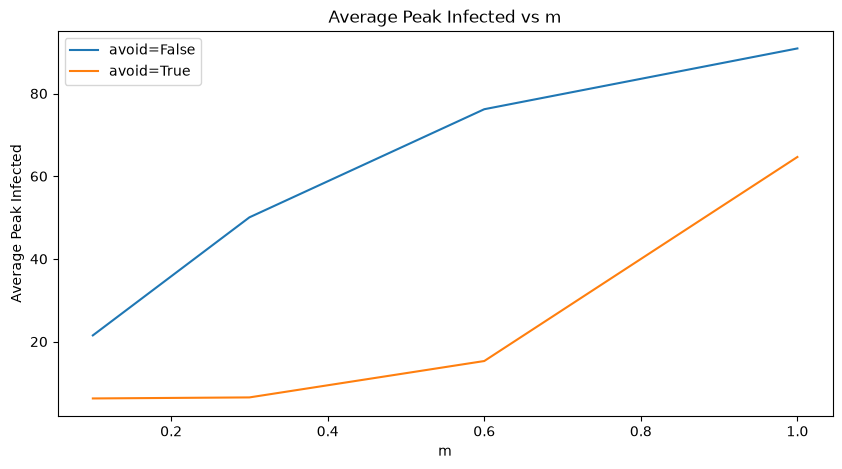

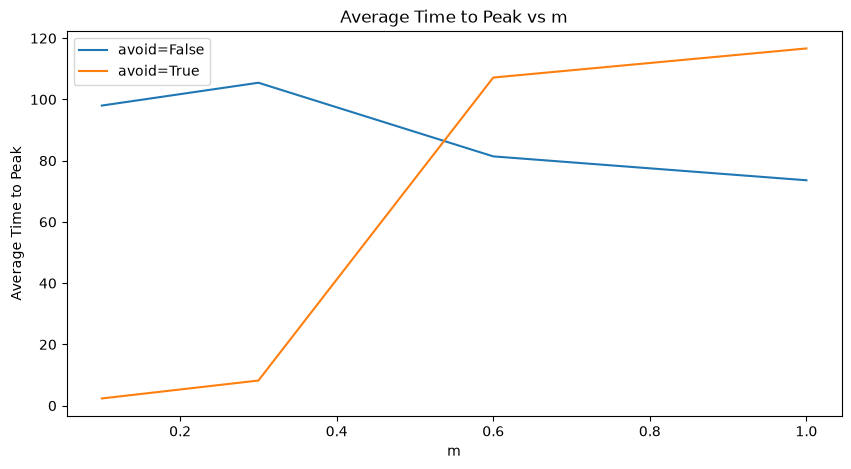

In [80]:
plt.figure(figsize=(10, 5))
for avoid in [False, True]:
    peak_values = [avg_peak_infected[(avoid, m)] for m in [1, 0.6, 0.3, 0.1]]
    plt.plot([1, 0.6, 0.3, 0.1], peak_values,label=f'avoid={avoid}')
plt.xlabel('m')
plt.ylabel('Average Peak Infected')
plt.title('Average Peak Infected vs m')
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
for avoid in [False, True]:
    time_to_peak_values = [avg_time_to_peak[(avoid, m)] for m in [1, 0.6, 0.3, 0.1]]
    plt.plot([1, 0.6, 0.3, 0.1], time_to_peak_values, label=f'avoid={avoid}')
plt.xlabel('m')
plt.ylabel('Average Time to Peak')
plt.title('Average Time to Peak vs m')
plt.legend()
plt.show()

#### Discuss how stricter or more relaxed distancing affects the epidemic

Stricter distancing is always better. Even though the average time to peak is early when people both avoid infected individuals as well as have reduced movement, the number of infected individuals at the peak is significantly lower. Therefore, the effects of distancing is monotonic - the stricter the better.

Below are numbers computed for the presentation slide.

In [77]:
# what is the diff between m=0.6 between avoid=True and avoid=False?
avg_peak_infected[(False, 0.6)] - avg_peak_infected[(True, 0.6)]

np.float64(60.900000000000006)

In [78]:
avg_peak_infected[(False, 1)] - avg_peak_infected[(True, 1)]

np.float64(26.25)